# HW HH
### Никита Коняхин

# A/B-тест «Похожие вакансии»

**Гипотеза.** После обычного отклика показываем похожие вакансии с быстрым
откликом. Соискателю легче откликнуться на подходящую вакансию, поэтому
релевантных откликов на соискателя становится больше.

| Роль | Метрика на соискателя | Критерий |
|---|---|---|
| Целевая | Релевантные отклики | Двусторонний тест Уэлча, α = 0,05 |
| Защитная | Приглашения | Односторонний тест на снижение, α = 0,05 |
| Информационные | Обычные отклики и просмотры вакансий | Двусторонние тесты Уэлча, α = 0,001 каждый |

Делим соискателей по `user_id` 50/50. Группа A видит обычный экран после
отклика, B видит блок. В эксперимент соискатель входит при первом
успешном обычном отклике, до показа блока. В анализ включаем всех вошедших,
в том числе тех, кто не совершил новых действий.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


users = pd.read_csv("users.csv")
logs = pd.read_csv("user_week_metrics.csv", parse_dates=["week_start"])

# Проверка данных
Проверяем ключи, даты, совпадение ролей и порядок счётчиков: приглашения ≤ релевантные отклики ≤ обычные отклики.

In [2]:
assert users.user_id.notna().all() and users.user_id.is_unique
assert logs.user_id.notna().all() and not logs.duplicated(["user_id", "week_start"]).any()
assert set(users.user_type) == {"APPLICANT", "EMPLOYER"}
assert logs.user_id.map(users.set_index("user_id").user_type).eq(logs.user_type).all()

weeks = pd.date_range("2026-03-09", periods=9, freq="W-MON")
assert set(logs.week_start) == set(weeks)
app_columns = ["responses_app", "relevant_responses_app", "invitations_app"]
emp_columns = ["responses_emp", "relevant_responses_emp", "invitations_emp"]
for role, columns, other in [
    ("APPLICANT", app_columns + ["vacancy_views_app"], emp_columns),
    ("EMPLOYER", emp_columns, app_columns + ["vacancy_views_app"]),
]:
    rows = logs.loc[logs.user_type.eq(role)]
    values = rows[columns]
    assert (np.isfinite(values) & values.ge(0) & values.mod(1).eq(0)).all().all()
    assert rows[other].isna().all().all()
    responses, relevant, invitations = columns[:3]
    assert (rows[responses].ge(rows[relevant]) & rows[relevant].ge(rows[invitations])).all()

app = logs.loc[logs.user_type.eq("APPLICANT")].copy()
app["trigger"] = app.responses_app.gt(0)
weekly = app.groupby("week_start").trigger.agg(["size", "sum", "mean"])
weekly.columns = ["Активные", "С откликом", "Доля"]
weekly["Доля"] = (weekly["Доля"] * 100).round(1)
print(f"Пользователей: {len(users):,}, строк в логах: {len(logs):,}. Проверки пройдены.")
print("Доля соискателей с откликом, %:")
print(weekly.to_string())

Пользователей: 388,000, строк в логах: 870,685. Проверки пройдены.
Доля соискателей с откликом, %:
            Активные  С откликом  Доля
week_start                            
2026-03-09    102701       94675  92.2
2026-03-16    103872       95857  92.3
2026-03-23    103090       95082  92.2
2026-03-30    101859       93844  92.1
2026-04-06    102791       94868  92.3
2026-04-13    103926       95994  92.4
2026-04-20    102599       94635  92.2
2026-04-27     53178       34259  64.4
2026-05-04     49522       31660  63.9


В обычные недели заходили 102–104 тыс. соискателей, около 92% из них откликались. 
В две майские недели показатели снизились до 50–53 тыс. и 64%. Поэтому основной расчёт делаем по неделям с 9 марта по 26 апреля.
Отдельно проверим сценарий с 06.04.2026 года, где на 4 и 5 недели приходятся шашлыки. 

In [3]:
TARGET, GUARD = app_columns[1:]
metrics = [TARGET, GUARD]
names = ["Релевантные отклики", "Приглашения"]
thresholds = pd.Series([1.7, 3.0], index=names)
ordinary = weeks[:7]
calendar = weeks[4:]


def user_totals(window):
    rows = app.loc[app.week_start.isin(window)]
    start = rows.loc[rows.trigger].groupby("user_id").week_start.min()
    rows = rows.loc[rows.week_start.ge(rows.user_id.map(start))]
    return rows.groupby("user_id")[metrics].sum()


def mde(window):
    totals = user_totals(window)
    n = len(totals) // 2
    critical = stats.norm.ppf([0.975, 0.95])
    return 100 * (critical + stats.norm.ppf(0.8)) * totals.std() * np.sqrt(2 / n) / totals.mean()


regular = pd.DataFrame([
    pd.DataFrame([mde(ordinary[i:i+k]) for i in range(len(ordinary)-k+1)]).max()
    for k in range(1, 6)
], index=range(1, 6))
seasonal = pd.DataFrame([mde(calendar[:k]) for k in range(1, 6)], index=range(1, 6))
regular.columns = seasonal.columns = names
summary = pd.concat({"Обычные (макс.)": regular, "Календарь": seasonal}, axis=1)
print(summary.round(3).to_string())

      Обычные (макс.)                       Календарь            
  Релевантные отклики Приглашения Релевантные отклики Приглашения
1               1.972       3.895               1.948       3.852
2               1.733       3.122               1.706       3.079
3               1.636       2.807               1.623       2.805
4               1.589       2.659               1.793       2.906
5               1.540       2.532               1.970       3.043


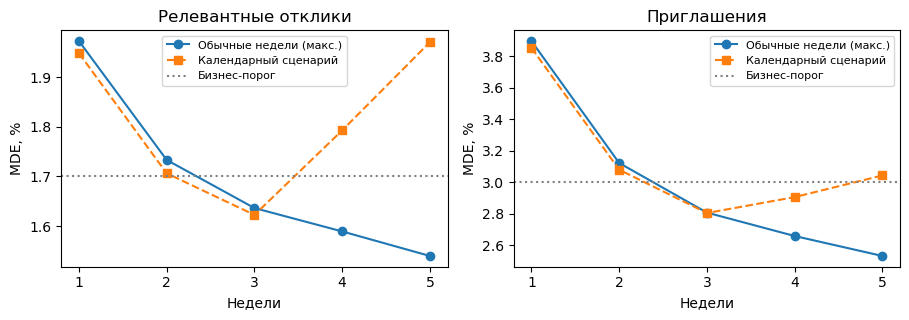

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.3))
for ax, metric in zip(axes, names):
    ax.plot(regular.index, regular[metric], "o-", label="Обычные недели (макс.)")
    ax.plot(seasonal.index, seasonal[metric], "s--", label="Календарный сценарий")
    ax.axhline(thresholds[metric], color="gray", linestyle=":", label="Бизнес-порог")
    ax.set(title=metric, xlabel="Недели", ylabel="MDE, %", xticks=regular.index)
    ax.legend(fontsize=8)
fig.tight_layout()

fig.savefig("mde.png", dpi=300, bbox_inches="tight")

plt.show()

In [5]:
forecast = regular.combine(seasonal, np.maximum)
fits = forecast.le(thresholds).all(axis=1)
duration = int(fits[fits].index[0])
end = pd.Timestamp("2027-04-05") + pd.Timedelta(days=7 * duration - 1)
print(f"Выбор: {duration} недели, 05.04.2027–{end:%d.%m.%Y}")
print(forecast.loc[duration].round(3).to_string())

Выбор: 3 недели, 05.04.2027–25.04.2027
Релевантные отклики    1.636
Приглашения            2.807


**Вывод:** 

Три полные недели с 5 по 25 апреля дают нужную чувствительность до майских праздников. При мощности 80% тест рассчитан на рост релевантных откликов от 1,64% и падение приглашений от 2,81% относительно нулевого эффекта. За 2 недели пороги не выполняются.
В обычные недели MDE постепенно падает (в тест входят новые соискатели).
В календарном сценарии на майских трафик растёт медленнее, а разброс сумм на соискателя увеличивается быстрее среднего, поэтому MDE растёт.

# A/A
Делим одних и тех же соискателей случайно 1 000 раз. В каждой итерации сравниваем средние двусторонним Уэлчем. Первое разбиение проверяем на SRM (проверяем, согласуется ли размер групп с ожидаемым сплитом 50/50).

In [6]:
y = user_totals(calendar[:duration])[TARGET].to_numpy(dtype=float)
rng = np.random.default_rng(20270405)
p_values = []
for run in range(1000):
    in_b = rng.integers(0, 2, size=len(y), dtype=np.int8).astype(bool)
    if run == 0:
        counts = [int((~in_b).sum()), int(in_b.sum())]
    p_values.append(stats.ttest_ind(y[in_b], y[~in_b], equal_var=False).pvalue)

hits = int(np.sum(np.array(p_values) < 0.05))
srm = stats.chisquare(counts)
print(f"A/A: {hits} из {len(p_values)}, доля {hits / len(p_values):.1%}. Ожидаем около 5%.")
print(f"A = {counts[0]}, B = {counts[1]}. SRM: χ² = {srm.statistic:.4f}, p = {srm.pvalue:.4f}.")

A/A: 45 из 1000, доля 4.5%. Ожидаем около 5%.
A = 99286, B = 98603. SRM: χ² = 2.3573, p = 0.1247.


Результат A/A близок к ожидаемым 5%. В первом разбиении признаков SRM нет.

# Риски и решение о запуске
- Разводим по аудитории тесты, которые меняют тот же экран, быстрый отклик или рекомендации.
- Набор заканчиваем до майских. Для приглашений учитываем заранее заданное окно ожидания ответа работодателя.
- Во время теста проверяем SRM, показы блока, ошибки и дубли откликов.
  При подтверждённом SRM или поломке логов останавливаем тест.
  Срок фиксируем заранее и не меняем по промежуточному p-value.
- Заранее выбираем срезы по платформе и региону. Для множественных сравнений применяем поправку Холма.
- Раскатываем блок, если цель значимо выросла минимум на 1,7% по точечной оценке и нижняя односторонняя 95%-я граница для приглашений выше −3%. Для целевой метрики также показываем доверительный интервал.